In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.linear_model import RidgeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("LA_AQS_2023.csv")
df.head()

,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
0,6,37,1103,68103,1,34.06659,-118.22688,WGS84,Ambient Min Temperature,24 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
2,6,37,1103,62201,1,34.06659,-118.22688,WGS84,Relative Humidity,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
3,6,37,1103,62101,1,34.06659,-118.22688,WGS84,Outdoor Temperature,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
4,6,37,1103,42603,1,34.06659,-118.22688,WGS84,Oxides of nitrogen (NOx),1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [3]:
df["Parameter Name"].unique()

<StringArray>
[   'Ambient Min Temperature',     'Nitrogen dioxide (NO2)',
          'Relative Humidity',        'Outdoor Temperature',
   'Oxides of nitrogen (NOx)',    'Wind Direction - Scalar',
   'Sample Min Baro Pressure', 'Wind Direction - Resultant',
   'Sample Max Baro Pressure',        'Elapsed Sample Time',
 ...
             'Iron (TSP) STP',        'Strontium (TSP) STP',
               'Acetaldehyde',               'Formaldehyde',
        'Methyl ethyl ketone',       'Molybdenum (TSP) STP',
        'Beryllium (TSP) STP',            'Propionaldehyde',
              'Butyraldehyde',              'Hexanaldehyde']
Length: 164, dtype: str

In [4]:
for name in df["Parameter Name"].unique():
    print(name)

Ambient Min Temperature
Nitrogen dioxide (NO2)
Relative Humidity
Outdoor Temperature
Oxides of nitrogen (NOx)
Wind Direction - Scalar
Sample Min Baro Pressure
Wind Direction - Resultant
Sample Max Baro Pressure
Elapsed Sample Time
Average Ambient Temperature
Ambient Max Temperature
Ultraviolet radiation
Solar radiation
Sample Flow Rate- CV
Wind Speed - Scalar
Wind Speed - Resultant
Average Ambient Pressure
Sample Volume
Ozone
Barometric pressure
PM2.5 - Local Conditions
PM10 Total 0-10um STP
Carbon monoxide
Sulfur dioxide
Nitric oxide (NO)
NOy - NO
Reactive oxides of nitrogen (NOy)
OC1 CSN_Rev Unadjusted PM2.5 LC
Sample Volume - Teflon Filter
Sample Flow Rate CV - Nylon Filter
Sample Volume - Nylon Filter
Sample Volume - Quartz Filter
Soil PM2.5 LC
Reconstructed Mass PM2.5 LC
EC1 PM2.5 LC
EC2 PM2.5 LC
EC3 CSN_Rev Unadjusted PM2.5 LC
OC CSN_Rev Unadjusted PM2.5 LC TOT
OC2 CSN_Rev Unadjusted PM2.5 LC
EC CSN_Rev Unadjusted PM2.5 LC TOT
OC CSN_Rev Unadjusted PM2.5 LC TOR
OP CSN_Rev Unadjus

In [5]:
df.columns

Index(['State Code', 'County Code', 'Site Number', 'Parameter Code', 'POC',
       'Latitude', 'Longitude', 'Datum', 'Parameter Name',
       'Duration Description', 'Pollutant Standard', 'Date (Local)', 'Year',
       'Day In Year (Local)', 'Units of Measure', 'Exceptional Data Type',
       'Nonreg Observation Count', 'Observation Count', 'Observation Percent',
       'Nonreg Arithmetic Mean', 'Arithmetic Mean',
       'Nonreg First Maximum Value', 'First Maximum Value',
       'First Maximum Hour', 'AQI', 'Daily Criteria Indicator', 'Tribe Name',
       'State Name', 'County Name', 'City Name', 'Local Site Name', 'Address',
       'MSA or CBSA Name', 'Data Source'],
      dtype='str')

In [6]:
ozone = df[df["Parameter Name"] == "Ozone"]
ozone.head()

,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
20,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
21,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,8-HR RUN AVG BEGIN HOUR,...,32,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
64,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
65,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,8-HR RUN AVG BEGIN HOUR,...,25,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
204,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [7]:
no2 = df[df["Parameter Name"] == "Nitrogen dioxide (NO2)"]
pm25 = df[df["Parameter Name"] == "PM2.5 - Local Conditions"]

no2.head()

,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
19,6,37,1103,42602,1,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,17,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
29,6,37,1103,42602,1,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,17,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
41,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
44,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,20,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [8]:
print(ozone["Units of Measure"].unique())
print(no2["Units of Measure"].unique())
print(pm25["Units of Measure"].unique())

<StringArray>
['Parts per million']
Length: 1, dtype: str
<StringArray>
['Parts per billion']
Length: 1, dtype: str
<StringArray>
['Micrograms/cubic meter (LC)']
Length: 1, dtype: str


In [9]:
print(ozone["Duration Description"].unique())
print(no2["Duration Description"].unique())
print(pm25["Duration Description"].unique())

<StringArray>
['1 HOUR', '8-HR RUN AVG BEGIN HOUR']
Length: 2, dtype: str
<StringArray>
['1 HOUR']
Length: 1, dtype: str
<StringArray>
['24 HOUR', '1 HOUR', '24-HR BLK AVG']
Length: 3, dtype: str


In [10]:
ozone = ozone[ozone["Duration Description"] == "1 HOUR"]
no2 = no2[no2["Duration Description"] == "1 HOUR"]
pm25 = pm25[pm25["Duration Description"] == "1 HOUR"]

ozone.head()

,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
20,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
64,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
204,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
228,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
271,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [11]:
ozone = ozone.copy()
ozone["O3_ppb"] = ozone["Arithmetic Mean"] * 1000

ozone[["Arithmetic Mean", "O3_ppb"]].head()

,Arithmetic Mean,O3_ppb
20,0.031708,31.708
64,0.015792,15.792
204,0.025000,25.000
228,0.020500,20.500
271,0.027375,27.375


In [12]:
print(ozone.shape)
print(no2.shape)
print(pm25.shape)

(273, 35)
(1092, 34)
(271, 34)


In [13]:
no2[["Date (Local)", "Site Number", "Arithmetic Mean"]].head()

,Date (Local),Site Number,Arithmetic Mean
1,2023-01-01,1103,4.816667
19,2023-01-01,1103,4.550000
29,2023-01-01,1103,4.550000
41,2023-01-01,1103,4.816667
44,2023-01-02,1103,14.720833


In [14]:
print(ozone["Site Number"].unique())
print(no2["Site Number"].unique())
print(pm25["Site Number"].unique())

[1103]
[1103]
[1103]


In [15]:
df_o3_no2 = pd.merge( ozone,no2,on="Date (Local)",suffixes=("_O3", "_NO2"))

df_o3_no2.shape

(1092, 68)

In [16]:
df_o3_no2[["Date (Local)", "O3_ppb", "Arithmetic Mean_NO2"]].head()

,Date (Local),O3_ppb,Arithmetic Mean_NO2
0,2023-01-01,31.708,4.816667
1,2023-01-01,31.708,4.550000
2,2023-01-01,31.708,4.550000
3,2023-01-01,31.708,4.816667
4,2023-01-02,15.792,14.720833


In [17]:
no2_daily = no2.groupby("Date (Local)")["Arithmetic Mean"].mean()

no2_daily.head()

Date (Local)
2023-01-01     4.683333
2023-01-02    15.068750
2023-01-03    11.662500
2023-01-04    14.363637
2023-01-05    11.027083
Name: Arithmetic Mean, dtype: float64

In [18]:
no2_daily = no2_daily.reset_index()

no2_daily.head()

,Date (Local),Arithmetic Mean
0,2023-01-01,4.683333
1,2023-01-02,15.068750
2,2023-01-03,11.662500
3,2023-01-04,14.363637
4,2023-01-05,11.027083


In [19]:
df_o3_no2 = pd.merge(ozone,no2_daily,on="Date (Local)")

df_o3_no2.shape

(273, 36)

In [20]:
df_o3_no2[["Date (Local)", "O3_ppb", "Arithmetic Mean_y"]].head()

,Date (Local),O3_ppb,Arithmetic Mean_y
0,2023-01-01,31.708,4.683333
1,2023-01-02,15.792,15.068750
2,2023-01-03,25.000,11.662500
3,2023-01-04,20.500,14.363637
4,2023-01-05,27.375,11.027083


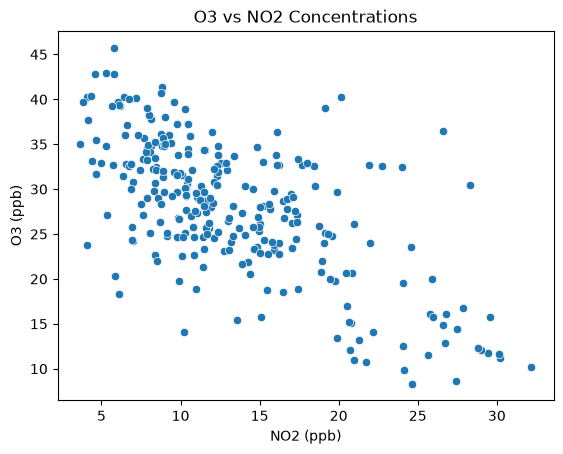

In [21]:
sns.scatterplot(data=df_o3_no2, x="Arithmetic Mean_y", y="O3_ppb")

plt.xlabel("NO2 (ppb)")
plt.ylabel("O3 (ppb)")
plt.title("O3 vs NO2 Concentrations")
plt.show()

In [22]:
pm25_daily = pm25.groupby("Date (Local)")["Arithmetic Mean"].mean()

pm25_daily = pm25_daily.reset_index()

pm25_daily.head()

,Date (Local),Arithmetic Mean
0,2023-01-01,5.087500
1,2023-01-02,9.187500
2,2023-01-03,4.312500
3,2023-01-04,4.266667
4,2023-01-05,6.704167


In [23]:
df_o3_pm25 = pd.merge(ozone, pm25_daily, on="Date (Local)")

df_o3_pm25.shape

(271, 36)

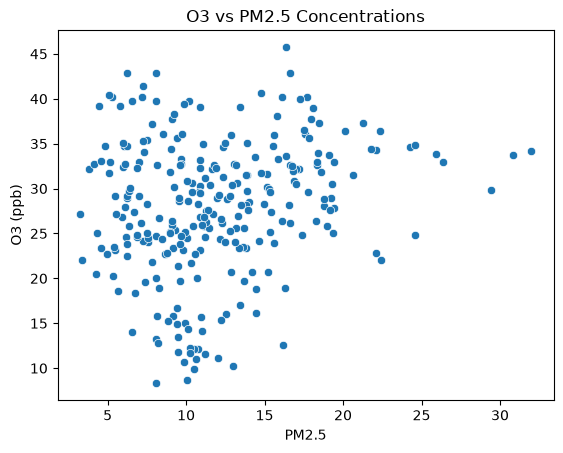

In [24]:
sns.scatterplot(data=df_o3_pm25, x="Arithmetic Mean_y", y="O3_ppb")

plt.xlabel("PM2.5")
plt.ylabel("O3 (ppb)")
plt.title("O3 vs PM2.5 Concentrations")
plt.show()

In [25]:
df_all = pd.merge(df_o3_no2,pm25_daily,on="Date (Local)")

df_all.shape

(271, 37)

In [26]:
df_all["Date (Local)"] = pd.to_datetime(df_all["Date (Local)"])

df_all = df_all[df_all["Date (Local)"].dt.month.isin([12, 1, 2, 6, 7, 8])].copy()

df_all["Season"] = np.where(df_all["Date (Local)"].dt.month.isin([6, 7, 8]), 1, 0)

In [27]:
X = df_all[["O3_ppb", "Arithmetic Mean_y", "Arithmetic Mean"]]
y = df_all["Season"]

clf = RidgeClassifier().fit(X, y)
clf.score(X, y)

0.8410596026490066

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42)

In [29]:
for alpha in [0.01, 0.1, 1, 10, 100]:
    clf = RidgeClassifier(alpha=alpha).fit(X_train, y_train)
    print(alpha, clf.score(X_train, y_train), clf.score(X_val, y_val))

0.01 0.8555555555555555 0.7666666666666667
0.1 0.8555555555555555 0.7666666666666667
1 0.8555555555555555 0.7666666666666667
10 0.8555555555555555 0.7666666666666667
100 0.8444444444444444 0.7666666666666667


In [30]:
clf = RidgeClassifier(alpha=1).fit(X_train, y_train)

print("Test accuracy:", clf.score(X_test, y_test))
print("Test error:", 1 - clf.score(X_test, y_test))

Test accuracy: 0.967741935483871
Test error: 0.032258064516129004


In [31]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y, test_size=0.2, random_state=10)

X_train2, X_val2, y_train2, y_val2 = train_test_split(
    X_train2, y_train2, test_size=0.25, random_state=10)

for alpha in [0.01, 0.1, 1, 10, 100]:
    clf2 = RidgeClassifier(alpha=alpha).fit(X_train2, y_train2)
    print(alpha, clf2.score(X_train2, y_train2), clf2.score(X_val2, y_val2))

0.01 0.8555555555555555 0.8
0.1 0.8555555555555555 0.8
1 0.8555555555555555 0.8
10 0.8555555555555555 0.8
100 0.8555555555555555 0.8


In [32]:
log_model = LogisticRegression(max_iter=1000).fit(X_train, y_train)

print("Logistic Regression:", log_model.score(X_test, y_test))
print("Ridge Classifier:", clf.score(X_test, y_test))

Logistic Regression: 0.967741935483871
Ridge Classifier: 0.967741935483871


1. Using these data as input, train a ridge classifier to predict if the measurements come from summer or winter. 

2. What cost function are you using? 

   I am using a penalized least-squares cost function with a ridge penalty to help prevent overfitting.


3. What is the optimal ridge penalty parameter based on your training data? 

    Based on my training data, the optimal ridge penalty parameters from those tested were 0.01, 0.1, 1, and 10, all with a training accuracy of 85.56%.


4. What is the optimal ridge penalty parameter on your validation data? 

All five alpha values gave the same validation accuracy of 76.67%, so there was no single best alpha among those tested.


5. What is your final model error? (Be sure to report the most honest error assessment).
 
 My final model had a test error of 3.23%, with a test accuracy of 96.77%. I used separate testing data to get an unbiased assessment of the model's accuracy.
 

6. If you redo your train/validation splits, do you get the same answers? 
 
 No, the results changed slightly when I used a different training and validation split. The validation accuracy increased from 76.67% to 80%, while the training accuracy stayed about the same.


7. Compare the ridge classifier with a logistic regression model. Which one performs the best?

Both the ridge classifier and logistic regression performed equally well, with a test accuracy of 96.77%.

